<div style="background:#0B2545;color:white;padding:18px 22px;border-radius:8px">
<div style="font-size:12px;letter-spacing:2px;opacity:.8">DATABANK ACADEMY · PROGRAMA EJECUTIVO EN GESTIÓN INTEGRAL DEL RIESGO DE CRÉDITO MINORISTA</div>
<div style="font-size:24px;font-weight:700;margin-top:6px">Módulo 4 · Sesión 2: Ensemble learning: bootstrap, bagging y random forests</div>
<div style="font-size:14px;margin-top:4px;opacity:.9">Laboratorio: sesgo-varianza de árboles, bootstrap, bagging desde cero, error OOB, decorrelación, importancia y AdaBoost</div>
</div>

## Objetivos de la sesión (2 horas)

1. Entender por qué los árboles son **inestables** y descomponer el error en **sesgo y varianza**.
2. Dominar el **bootstrap** (Efron, 1979): remuestreo, el 63,2 % y la estimación del error estándar.
3. Derivar e implementar **bagging** (Breiman, 1996): por qué promediar reduce varianza y el error *out-of-bag*.
4. Entender **random forests** (Breiman, 2001): cómo la selección aleatoria de variables reduce la correlación entre árboles.
5. Presentar la idea del **boosting** como estrategia complementaria: reducir **sesgo** de forma secuencial.

| Bloque | Tiempo | Contenido |
|---|---|---|
| 1 | 20 min | Inestabilidad de los árboles y sesgo-varianza |
| 2 | 20 min | Bootstrap |
| 3 | 30 min | Bagging desde cero y error OOB |
| 4 | 25 min | Random forests: decorrelación e importancia |
| 5 | 15 min | Del bagging al boosting: AdaBoost como puente |
| 6 | 10 min | Ejercicios |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
AZUL, ROJO, VERDE, GRIS, ORO = "#0B2545", "#C8102E", "#2E8B57", "#8D99AE", "#E0A100"
DATA = Path("../datos")

import warnings; warnings.filterwarnings("ignore")
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, log_loss
app = pd.read_csv(DATA / "hc_application_sintetico.csv").drop_duplicates()
app["EDAD"] = -app.DAYS_BIRTH / 365.25
app["RCI"] = app.AMT_ANNUITY / (app.AMT_INCOME_TOTAL / 12)
app["EXT1"] = app.EXT_SOURCE_1.fillna(-1); app["EXT2"] = app.EXT_SOURCE_2.fillna(-1); app["EXT3"] = app.EXT_SOURCE_3.fillna(-1)
app["ANTIG"] = np.where(app.DAYS_EMPLOYED == 365243, -1, -app.DAYS_EMPLOYED / 365.25)
app["LTI"] = app.AMT_CREDIT / app.AMT_INCOME_TOTAL
FEATS = ["EXT1", "EXT2", "EXT3", "EDAD", "RCI", "ANTIG", "LTI", "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_REQ_CREDIT_BUREAU_YEAR", "REGION_RATING_CLIENT", "CNT_CHILDREN"]
dev = app[app.FECHA_SOLICITUD < "2025-01"]; oot = app[app.FECHA_SOLICITUD >= "2025-01"]
X, y, Xo, yo = dev[FEATS].values, dev.TARGET.values, oot[FEATS].values, oot.TARGET.values
rng = np.random.default_rng(0)
print(X.shape, Xo.shape)

(45092, 12) (14908, 12)


## 1. Inestabilidad de los árboles y la descomposición sesgo-varianza
Para un estimador $\hat f$ entrenado con una muestra aleatoria $\mathcal{D}$, el error cuadrático esperado en un punto $x$ se descompone en:
$$E_{\mathcal{D}}\big[(\hat f(x) - f(x))^2\big] = \underbrace{\big(E[\hat f(x)] - f(x)\big)^2}_{\text{sesgo}^2} + \underbrace{E\big[(\hat f(x) - E[\hat f(x)])^2\big]}_{\text{varianza}}$$
Un árbol **profundo** tiene sesgo bajo y varianza alta; uno **poco profundo**, lo contrario. Medimos la varianza de la PD predicha para los mismos clientes cuando el árbol se entrena con muestras distintas.

In [2]:
clientes = Xo[:500]
res = []
for prof in [2, 4, 6, 10, None]:
    preds = []
    for b in range(30):
        idx = rng.choice(len(y), 15000, replace=False)
        preds.append(DecisionTreeClassifier(max_depth=prof, min_samples_leaf=20, random_state=b).fit(X[idx], y[idx]).predict_proba(clientes)[:, 1])
    preds = np.array(preds)
    res.append({"profundidad": str(prof), "varianza media de la PD": preds.var(axis=0).mean(), "desv. media de la PD": preds.std(axis=0).mean()})
display(pd.DataFrame(res).set_index("profundidad").style.format("{:.5f}"))
estructuras = []
for _ in range(20):
    i = rng.choice(len(y), 3000, replace=False)
    t = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X[i], y[i]).tree_
    estructuras.append({"raíz": FEATS[t.feature[0]], "umbral raíz": t.threshold[0],
                        "hijo izq.": FEATS[t.feature[t.children_left[0]]], "hijo der.": FEATS[t.feature[t.children_right[0]]]})
e = pd.DataFrame(estructuras)
print("20 árboles de profundidad 3, cada uno con 3 000 clientes distintos:")
print(f"  raíz: {e['raíz'].value_counts().to_dict()} | umbral entre {e['umbral raíz'].min():.3f} y {e['umbral raíz'].max():.3f}")
print(f"  variable del hijo izquierdo: {e['hijo izq.'].value_counts().to_dict()}")
print(f"  variable del hijo derecho:   {e['hijo der.'].value_counts().to_dict()}")

,varianza media de la PD,desv. media de la PD
profundidad,,
2,0.00057,0.01798
4,0.00138,0.02879
6,0.00262,0.03880
10,0.00764,0.07294
None,0.01138,0.09407


20 árboles de profundidad 3, cada uno con 3 000 clientes distintos:
  raíz: {'EXT2': 20} | umbral entre 0.303 y 0.601
  variable del hijo izquierdo: {'EXT2': 7, 'EXT3': 6, 'EDAD': 3, 'RCI': 2, 'ANTIG': 1, 'AMT_CREDIT': 1}
  variable del hijo derecho:   {'EXT2': 15, 'RCI': 3, 'EDAD': 2}


**Lectura:** a mayor profundidad, la PD predicha para un mismo cliente varía mucho más entre muestras. Con muestras pequeñas, aunque la raíz sea siempre `EXT2` (la variable dominante), su **umbral** se mueve y las variables del **segundo nivel** cambian de un árbol a otro: la estructura (y las reglas que se comunicarían al negocio) no es estable. Ésta es la motivación de los ensembles: si los árboles profundos tienen poco sesgo pero mucha varianza, **promediarlos** puede reducir la varianza sin aumentar el sesgo.

## 2. El bootstrap (Efron, 1979)
Una **muestra bootstrap** es una muestra de tamaño $n$ extraída **con reposición** de los datos. Dos hechos clave:
- La probabilidad de que un caso **no** sea elegido es $(1 - 1/n)^n \to e^{-1} \approx 0{,}368$: cada muestra bootstrap contiene ~**63,2 %** de casos distintos. El 36,8 % restante es *out-of-bag* (OOB).
- La variabilidad de un estadístico entre muestras bootstrap aproxima su **distribución muestral** (Módulo 2).

In [3]:
n = len(y)
unicos = [len(np.unique(rng.integers(0, n, n))) / n for _ in range(200)]
print(f"Fracción de casos distintos por muestra bootstrap: {np.mean(unicos):.4f} (teoría: 1 − e⁻¹ = {1 - np.exp(-1):.4f})")
ns = [5, 10, 50, 100, 1000, 10000]
print("(1 − 1/n)^n:", {k: round((1 - 1 / k) ** k, 4) for k in ns})

Fracción de casos distintos por muestra bootstrap: 0.6320 (teoría: 1 − e⁻¹ = 0.6321)
(1 − 1/n)^n: {5: 0.3277, 10: 0.3487, 50: 0.3642, 100: 0.366, 1000: 0.3677, 10000: 0.3679}


## 3. Bagging (*bootstrap aggregating*, Breiman, 1996)
**Algoritmo:** para $b = 1, \dots, B$: tomar una muestra bootstrap y entrenar un árbol profundo $\hat f_b$. Predecir con el promedio $\hat f_{bag}(x) = \frac{1}{B}\sum_b \hat f_b(x)$.

**¿Por qué reduce la varianza?** Si cada árbol tiene varianza $\sigma^2$ y la correlación entre dos árboles es $\rho$:
$$\text{Var}\big(\hat f_{bag}(x)\big) = \rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2$$
Al aumentar $B$, el segundo término desaparece, pero el primero **no**: la correlación entre árboles limita la ganancia. Bagging no aumenta el sesgo (cada árbol sigue siendo de bajo sesgo).

**Error out-of-bag:** cada caso se predice solo con los árboles que **no** lo vieron (~37 % de ellos). Es una estimación de error de prueba casi gratuita.

Bagging de 100 árboles en 41 s | cada caso fue OOB en 36.8 árboles en promedio (≈ 36,8)
AUC OOB (desarrollo) = 0.7385 | AUC fuera de tiempo con 100 árboles = 0.7448


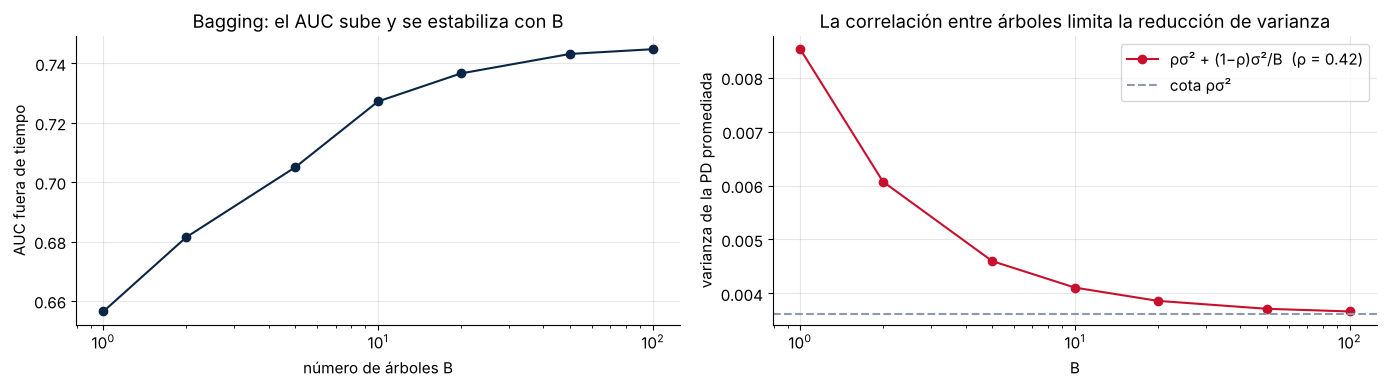

scikit-learn BaggingClassifier: AUC fuera de tiempo = 0.7465


In [4]:
def bagging_desde_cero(X, y, Xt, B=100, **kw):
    n = len(y); pred_t = np.zeros((B, len(Xt))); oob_sum = np.zeros(n); oob_cnt = np.zeros(n)
    for b in range(B):
        idx = rng.integers(0, n, n); oob = np.setdiff1d(np.arange(n), idx)
        arbol = DecisionTreeClassifier(random_state=b, **kw).fit(X[idx], y[idx])
        pred_t[b] = arbol.predict_proba(Xt)[:, 1]
        oob_sum[oob] += arbol.predict_proba(X[oob])[:, 1]; oob_cnt[oob] += 1
    return pred_t, oob_sum / np.maximum(oob_cnt, 1), oob_cnt
import time; t0 = time.time()
pred_t, p_oob, cnt = bagging_desde_cero(X, y, Xo, B=100, min_samples_leaf=50)
print(f"Bagging de 100 árboles en {time.time() - t0:.0f} s | cada caso fue OOB en {cnt.mean():.1f} árboles en promedio (≈ 36,8)")
Bs = [1, 2, 5, 10, 20, 50, 100]
auc_B = [roc_auc_score(yo, pred_t[:b].mean(0)) for b in Bs]
print(f"AUC OOB (desarrollo) = {roc_auc_score(y, p_oob):.4f} | AUC fuera de tiempo con 100 árboles = {auc_B[-1]:.4f}")
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(Bs, auc_B, "o-", color=AZUL); ax[0].set_xscale("log"); ax[0].set_xlabel("número de árboles B"); ax[0].set_ylabel("AUC fuera de tiempo"); ax[0].set_title("Bagging: el AUC sube y se estabiliza con B")
# Var(promedio) vs B y la cota rho*sigma^2
s2 = pred_t.var(axis=0).mean(); rho = np.mean([np.corrcoef(pred_t[i], pred_t[i + 1])[0, 1] for i in range(0, 98, 2)])
teo = [rho * s2 + (1 - rho) * s2 / b for b in Bs]
emp = [np.mean([pred_t[rng.choice(100, b, replace=False)].mean(0) for _ in range(10)], axis=0) for b in Bs]
ax[1].plot(Bs, teo, "o-", color=ROJO, label=f"ρσ² + (1−ρ)σ²/B  (ρ = {rho:.2f})"); ax[1].axhline(rho * s2, color=GRIS, ls="--", label="cota ρσ²")
ax[1].set_xscale("log"); ax[1].set_xlabel("B"); ax[1].set_ylabel("varianza de la PD promediada"); ax[1].legend(); ax[1].set_title("La correlación entre árboles limita la reducción de varianza")
plt.tight_layout(); plt.show()
sk_bag = BaggingClassifier(DecisionTreeClassifier(min_samples_leaf=50), n_estimators=100, oob_score=True, n_jobs=-1, random_state=0).fit(X, y)
print(f"scikit-learn BaggingClassifier: AUC fuera de tiempo = {roc_auc_score(yo, sk_bag.predict_proba(Xo)[:, 1]):.4f}")

## 4. Random forests (Breiman, 2001)
Para bajar la correlación $\rho$ entre árboles, random forest agrega una segunda fuente de aleatoriedad: en **cada partición** solo se consideran $m < p$ variables elegidas al azar (`max_features`; típicamente $\sqrt{p}$ en clasificación). Los árboles se vuelven más distintos entre sí y el promedio reduce más la varianza.

In [5]:
res = []
for mf in [1, 2, 3, 6, len(FEATS)]:
    rf = RandomForestClassifier(n_estimators=200, max_features=mf, min_samples_leaf=50, n_jobs=-1, random_state=0, oob_score=True).fit(X, y)
    arboles = np.array([t.predict_proba(Xo[:2000])[:, 1] for t in rf.estimators_[:40]])
    c = np.corrcoef(arboles); rho_rf = c[np.triu_indices_from(c, 1)].mean()
    res.append({"max_features": mf, "ρ entre árboles": rho_rf, "AUC OOB": roc_auc_score(y, rf.oob_decision_function_[:, 1]), "AUC fuera de tiempo": roc_auc_score(yo, rf.predict_proba(Xo)[:, 1])})
display(pd.DataFrame(res).set_index("max_features").style.format("{:.4f}").set_caption("max_features = 12 equivale a bagging"))

,ρ entre árboles,AUC OOB,AUC fuera de tiempo
max_features,,,
1,0.3782,0.7471,0.7424
2,0.4650,0.7503,0.7466
3,0.4840,0.7511,0.7499
6,0.4983,0.7469,0.7490
12,0.4912,0.7446,0.7467


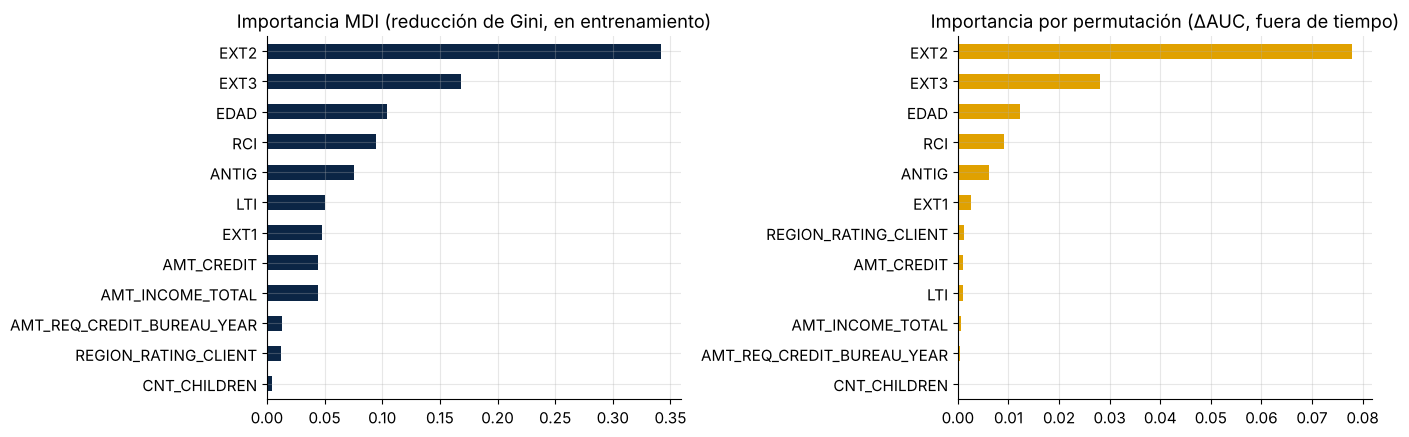

In [6]:
rf = RandomForestClassifier(n_estimators=300, max_features=3, min_samples_leaf=50, n_jobs=-1, random_state=0).fit(X, y)
mdi = pd.Series(rf.feature_importances_, index=FEATS)
perm = pd.Series(permutation_importance(rf, Xo, yo, scoring="roc_auc", n_repeats=5, random_state=0, n_jobs=-1).importances_mean, index=FEATS)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
mdi.sort_values().plot(kind="barh", ax=ax[0], color=AZUL); ax[0].set_title("Importancia MDI (reducción de Gini, en entrenamiento)")
perm.sort_values().plot(kind="barh", ax=ax[1], color=ORO); ax[1].set_title("Importancia por permutación (ΔAUC, fuera de tiempo)")
plt.tight_layout(); plt.show()

**Lectura:** la importancia MDI (*mean decrease in impurity*) favorece a variables continuas con muchos cortes posibles (`AMT_INCOME_TOTAL`, `AMT_CREDIT`), aunque su aporte real sea bajo. La importancia **por permutación fuera de muestra** es más confiable. Lo retomaremos con SHAP en el Módulo 7.

## 5. Del bagging al boosting
Bagging y random forest **reducen varianza** promediando modelos **independientes** entrenados en paralelo. El **boosting** sigue la estrategia opuesta: entrena modelos **débiles** (de alto sesgo, p. ej. árboles de profundidad 1-3) en **secuencia**, cada uno corrigiendo los errores de los anteriores, para **reducir sesgo**.

**AdaBoost** (Freund y Schapire, 1997) fue el primer algoritmo exitoso: aumenta el peso de los casos mal clasificados en cada ronda. Friedman, Hastie y Tibshirani (2000) mostraron que AdaBoost equivale a ajustar un **modelo aditivo** minimizando la pérdida exponencial paso a paso. Friedman (2001) generalizó la idea a **cualquier pérdida diferenciable**: el **gradient boosting** de la sesión 3.

In [7]:
comp = {}
for nombre, m in [("Árbol podado (1 árbol)", DecisionTreeClassifier(min_samples_leaf=50, ccp_alpha=1.2e-4, random_state=0)),
                  ("Bagging (100 árboles)", BaggingClassifier(DecisionTreeClassifier(min_samples_leaf=50), n_estimators=100, n_jobs=-1, random_state=0)),
                  ("Random forest (300 árboles)", rf),
                  ("AdaBoost (200 tocones)", AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=200, learning_rate=0.5, random_state=0))]:
    if nombre != "Random forest (300 árboles)": m.fit(X, y)
    p = m.predict_proba(Xo)[:, 1]
    comp[nombre] = {"AUC fuera de tiempo": roc_auc_score(yo, p), "PD media": p.mean(), "tasa observada": yo.mean()}
pd.DataFrame(comp).T.style.format({"AUC fuera de tiempo": "{:.4f}", "PD media": "{:.2%}", "tasa observada": "{:.2%}"})

,AUC fuera de tiempo,PD media,tasa observada
Árbol podado (1 árbol),0.7183,7.98%,5.86%
Bagging (100 árboles),0.7465,8.02%,5.86%
Random forest (300 árboles),0.7501,8.04%,5.86%
AdaBoost (200 tocones),0.7457,28.71%,5.86%


**Lectura:** los ensembles superan con claridad al árbol individual. AdaBoost discrimina bien pero sus "probabilidades" **no están calibradas** (se concentran cerca de 0,5): optimiza una pérdida exponencial, no la log-verosimilitud. Gradient boosting con pérdida logística resuelve esto (sesión 3).

| | Bagging / Random forest | Boosting |
|---|---|---|
| Modelos base | Árboles profundos (bajo sesgo, alta varianza) | Árboles poco profundos (alto sesgo, baja varianza) |
| Entrenamiento | En paralelo, independientes | Secuencial, cada uno corrige al anterior |
| Reduce | Varianza | Sesgo (y algo de varianza con shrinkage y submuestreo) |
| Riesgo de sobreajuste con más árboles | Bajo | Alto si no se controla (learning rate, early stopping) |

## 6. Ejercicios
1. Repite el bagging con árboles de profundidad 3. ¿Cuánto mejora frente a un solo árbol de profundidad 3? ¿Por qué menos que con árboles profundos?
2. Grafica el error OOB del random forest en función del número de árboles (`warm_start=True`).
3. Calibra la salida de AdaBoost con regresión isotónica y compara el log-loss.
4. ¿Qué `max_features` minimiza el log-loss OOB?